# Notebook 3 - Network Analytics & Web UI Export
## Forensic Network Analysis: The Epstein Corpus

**Pipeline:**
1. Pruning & Cleaning post-NLP  
2. Costruzione DiGraph pesato (NetworkX)  
3. Metriche: Degree · Betweenness · PageRank · Eigenvector  
4. Community Detection (Louvain)  
5. **RQ1** — Context Drift (analisi temporale)  
6. **RQ2** — The Brokers (Unknown entities)  
7. **RQ3** — Contextual Influence (metriche per dominio)  
8. Export JSON per React/WebGL  


In [1]:
# Import e configurazione

import pandas as pd
import networkx as nx
import community.community_louvain as community_louvain
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import numpy as np
import json
import re
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({'figure.autolayout': True, 'figure.dpi': 120})

# Palette colori coerente per tutte le visualizzazioni
PALETTE = {
    "Legal":       "#E53935",   # Rosso
    "Social":      "#1E88E5",   # Blu
    "Logistical":  "#43A047",   # Verde
    "Unknown":     "#9E9E9E"    # Grigio
}

EDGES_PATH = '../data/edges_classified.csv'
print("Configurazione completata. Librerie caricate.")


Configurazione completata. Librerie caricate.


In [2]:
# Normalizziamo le etichette in etichette corte (Legal/Social/Logistical).

df_raw = pd.read_csv(EDGES_PATH)
print(f"Righe totali nel CSV classificato: {len(df_raw):,}")

# Label mapping
label_map = {
    "logistical coordination or travel planning":            "Logistical",
    "social networking, personal or political communication":"Social",
    "legal procedural, investigative or oversight action":   "Legal"
}
df_raw['edge_label'] = df_raw['semantic_category'].map(label_map).fillna('Unknown')

# Confidence threshold (> 0.7 = alta certezza del modello)
df_confident = df_raw[
    (df_raw['edge_label'] != 'Unknown') &
    (df_raw['confidence'] >= 0.70)
].copy()

print(f"Archi dopo filtro confidence ≥ 0.70: {len(df_confident):,}")
print(f"Archi scartati (bassa conf. o errori): {len(df_raw) - len(df_confident):,}")
print(f"\nDistribuzione classi:")
print(df_confident['edge_label'].value_counts().to_string())


Righe totali nel CSV classificato: 107,021
Archi dopo filtro confidence ≥ 0.70: 66,467
Archi scartati (bassa conf. o errori): 40,554

Distribuzione classi:
edge_label
Legal         34095
Social        27310
Logistical     5062


In [3]:
# Profiling delle entità Unknown
# Usiamo una regex per catturare tutte le varianti (non un blacklist statico).

UNKNOWN_PATTERN = re.compile(
    r'\b(unknown|jane doe|john doe|individual\s*#?\d*|victim\s*#?\d*|'
    r'minor\s*#?\d*|girl\s*#?\d*|person\s*[a-z]?\b|unidentified|'
    r'himself|herself|staff member|employee)\b',
    re.IGNORECASE
)


def is_unknown(name: str) -> bool:
    return bool(UNKNOWN_PATTERN.search(str(name).strip()))

df_confident['actor_is_unknown'] = df_confident['actor'].apply(is_unknown)
df_confident['target_is_unknown'] = df_confident['target'].apply(is_unknown)

# Conteggio
n_unk_actor  = df_confident['actor_is_unknown'].sum()
n_unk_target = df_confident['target_is_unknown'].sum()
unique_unk   = pd.concat([
    df_confident[df_confident['actor_is_unknown']]['actor'],
    df_confident[df_confident['target_is_unknown']]['target']
]).str.lower().str.strip().unique()

print(f"Archi con attore Unknown:  {n_unk_actor:,} ({n_unk_actor/len(df_confident)*100:.1f}%)")
print(f"Archi con target Unknown:  {n_unk_target:,} ({n_unk_target/len(df_confident)*100:.1f}%)")
print(f"Varianti uniche di Unknown trovate: {len(unique_unk)}")
print(f"\nTop 20 varianti:")
top_unk = pd.concat([
    df_confident[df_confident['actor_is_unknown']]['actor'],
    df_confident[df_confident['target_is_unknown']]['target']
]).value_counts().head(20)
print(top_unk.to_string())


Archi con attore Unknown:  7,818 (11.8%)
Archi con target Unknown:  5,980 (9.0%)
Varianti uniche di Unknown trovate: 2484

Top 20 varianti:
unknown person A                                                      5121
unknown person B                                                       875
unknown person                                                         314
unknown person C                                                       250
unknown recipient                                                      194
unknown witness                                                        127
victim                                                                 105
unknown person D                                                        92
unknown person A (HOUSE_OVERSIGHT_027165) (HOUSE_OVERSIGHT_027165)      79
Jane Doe #3                                                             78
unknown person A (HOUSE_OVERSIGHT_025707) (HOUSE_OVERSIGHT_025707)      67
Jane Doe                           

In [4]:
# Hard Pruning per rimuovere il rumore semantico
# Rimuoviamo SOLO le entità che non hanno valore semantico nemmeno
# come broker (es. pronti riflessivi come 'himself', 'herself').

NOISE_ONLY_PATTERN = re.compile(
    r'^(himself|herself|staff member|employee|the government|'
    r'the court|the public|others|various|several|all parties)$',
    re.IGNORECASE
)

def is_noise(name: str) -> bool:
    return bool(NOISE_ONLY_PATTERN.match(str(name).strip()))

df_confident['actor_is_noise'] = df_confident['actor'].apply(is_noise)
df_confident['target_is_noise'] = df_confident['target'].apply(is_noise)

df_clean = df_confident[
    ~df_confident['actor_is_noise'] &
    ~df_confident['target_is_noise']
].copy()

print(f"Archi prima del pruning: {len(df_confident):,}")
print(f"Archi dopo hard pruning: {len(df_clean):,}")
print(f"Rimossi: {len(df_confident) - len(df_clean):,}")


Archi prima del pruning: 66,467
Archi dopo hard pruning: 66,447
Rimossi: 20


In [5]:
# Edge Aggregation (Costruzione del peso degli archi)
# Se Epstein incontra persona x 100 volte in documenti diversi, creiamo
# un solo arco di peso 100. Raggruppiamo per (actor, target, edge_label).

edges_agg = (
    df_clean
    .groupby(['actor', 'target', 'edge_label'])
    .agg(
        weight=('edge_label', 'count'),
        avg_confidence=('confidence', 'mean')
    )
    .reset_index()
)

print(f"Archi unici (aggregati) nel grafo: {len(edges_agg):,}")
print(f"\nDistribuzione per categoria:")
print(edges_agg.groupby('edge_label')['weight'].agg(['count','sum','mean']).round(2))


Archi unici (aggregati) nel grafo: 40,535

Distribuzione per categoria:
            count    sum  mean
edge_label                    
Legal       21708  34080  1.57
Logistical   2192   5062  2.31
Social      16635  27303  1.64


In [6]:
# Costruzione del grafo pesato (NetworkX)
# Usiamo un DiGraph (orientato) perché la direzione conta:
# 'Epstein contacted Maxwell' ≠ 'Maxwell contacted Epstein'.
# Il peso dell'arco = numero di interazioni documentate tra le due entità in quella categoria semantica.

G_full = nx.DiGraph()

for _, row in edges_agg.iterrows():
    G_full.add_edge(
        row['actor'],
        row['target'],
        weight=row['weight'],
        category=row['edge_label'],
        avg_confidence=row['avg_confidence']
    )

print(f"Grafo costruito:")
print(f"  Nodi totali:  {G_full.number_of_nodes():,}")
print(f"  Archi totali: {G_full.number_of_edges():,}")
print(f"  Densità:      {nx.density(G_full):.6f}")

# Componente connessa principale (per escludere isole)
G_undir = G_full.to_undirected(reciprocal=False)
# Nota: reciprocal=False conserva l'arco se esiste almeno in una direzione.
# reciprocal=True richiederebbe l'arco in entrambe le direzioni (troppo restrittivo).
components = sorted(nx.connected_components(G_undir), key=len, reverse=True)
print(f"\nComponenti connesse: {len(components)}")
print(f"Componente principale: {len(components[0]):,} nodi ({len(components[0])/G_full.number_of_nodes()*100:.1f}%)")
print(f"Nodi isolati (componenti da 1): {sum(1 for c in components if len(c)==1)}")


Grafo costruito:
  Nodi totali:  33,402
  Archi totali: 39,532
  Densità:      0.000035

Componenti connesse: 3852
Componente principale: 24,169 nodi (72.4%)
Nodi isolati (componenti da 1): 8


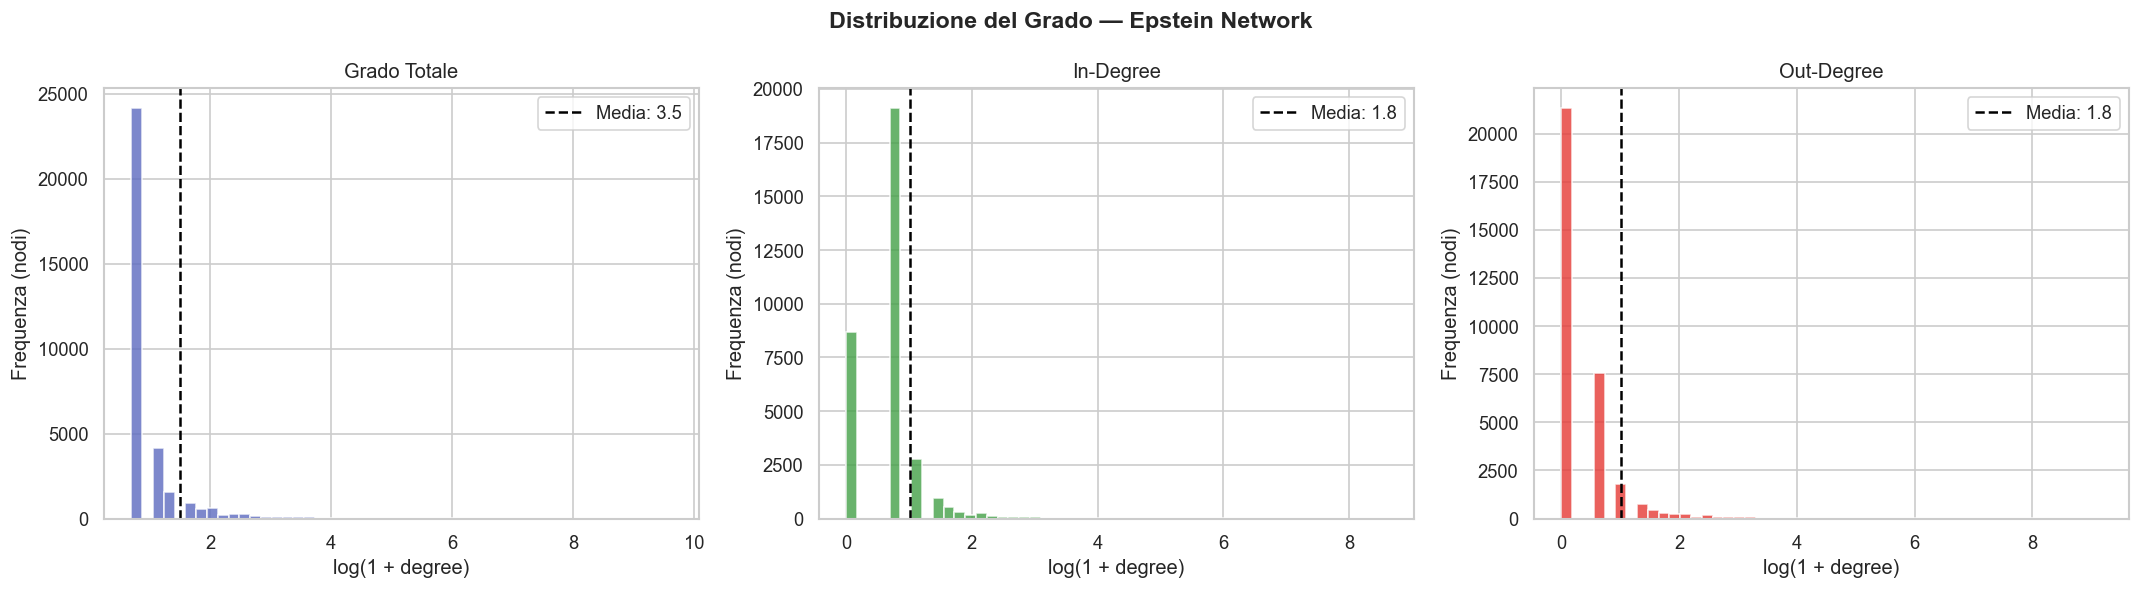

Top 10 nodi per grado pesato totale:
                    degree
Jeffrey Epstein      15133
unknown person A      3700
Donald Trump          2427
Alan M. Dershowitz    1291
Ehud Barak            1177
Steve Bannon           830
Ghislaine Maxwell      641
Edward Snowden         614
Bill Clinton           564
Barack Obama           521


In [7]:
# Distribuzione del grado (Power Law)
# Un network reale di relazioni sociali/forensiche segue tipicamente una
# distribuzione power-law: pochi nodi con grado altissimo (hub), molti con grado basso.

degrees = [d for _, d in G_full.degree(weight='weight')]
in_degrees  = [d for _, d in G_full.in_degree(weight='weight')]
out_degrees = [d for _, d in G_full.out_degree(weight='weight')]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Distribuzione del Grado — Epstein Network', fontsize=14, fontweight='bold')

for ax, data, title, color in zip(
    axes,
    [degrees, in_degrees, out_degrees],
    ['Grado Totale', 'In-Degree', 'Out-Degree'],
    ['#5C6BC0', '#43A047', '#E53935']
):
    ax.hist(np.log1p(data), bins=50, color=color, alpha=0.8, edgecolor='white')
    ax.set_title(title)
    ax.set_xlabel('log(1 + degree)')
    ax.set_ylabel('Frequenza (nodi)')
    ax.axvline(np.log1p(np.mean(data)), color='black', linestyle='--',
               label=f'Media: {np.mean(data):.1f}')
    ax.legend()

plt.tight_layout()
plt.show()

# Top 10 nodi per grado pesato totale
top_degree = pd.Series(dict(G_full.degree(weight='weight'))).sort_values(ascending=False).head(10)
print("Top 10 nodi per grado pesato totale:")
print(top_degree.to_frame('degree').to_string())


In [8]:
# Calcoliamo 4 metriche sul grafo completo. Servono tutte per la RQ3.
# - Degree Centrality:      connessioni dirette (chi è più attivo?)
# - Betweenness Centrality: quanti shortest paths passano per questo nodo?
#                           → Risponde a RQ2 (broker strutturali)
#                           → Approssimata con k=500 per ragioni computazionali
#                             (Brandes, 2001 — standard su grafi large-scale)
# - PageRank:               influenza propagata iterativamente
# - Eigenvector Centrality: connessione a nodi influenti

print("Calcolo metriche di centralità...")

degree_w    = dict(G_full.degree(weight='weight'))
in_degree_w = dict(G_full.in_degree(weight='weight'))
out_degree_w= dict(G_full.out_degree(weight='weight'))

print("  Betweenness Centrality (campionamento k=500)...")
k_samples   = min(500, G_full.number_of_nodes())
betweenness = nx.betweenness_centrality(
    G_full, k=k_samples, normalized=True, weight='weight', seed=42
)
print(f"  Completata su campione k={k_samples} (approssimazione Brandes 2001)")

print("  PageRank...")
pagerank    = nx.pagerank(G_full, alpha=0.85, weight='weight')

print("  Eigenvector Centrality...")
try:
    eigenvector = nx.eigenvector_centrality(G_full, max_iter=1000, weight='weight')
except nx.PowerIterationFailedConvergence:
    print("  ⚠ Eigenvector non convergente su DiGraph, uso grafo non orientato.")
    eigenvector = nx.eigenvector_centrality(G_undir, max_iter=1000, weight='weight')

# Community Detection (Louvain su grafo non orientato)
print("  Community Detection (Louvain)...")
# resolution > 1 = comunità più grandi e meno numerose
# 1.5 è un valore standard per grafi forensi sparse
partition = community_louvain.best_partition(
    G_undir, weight='weight', random_state=42, resolution=1.5
)
n_communities = len(set(partition.values()))
print(f"  Comunità rilevate: {n_communities}")

# DataFrame centralità
df_centrality = pd.DataFrame({
    'degree':      degree_w,
    'in_degree':   in_degree_w,
    'out_degree':  out_degree_w,
    'betweenness': betweenness,
    'pagerank':    pagerank,
    'eigenvector': eigenvector,
    'community':   partition
})

print(f"\nMetriche calcolate per {len(df_centrality):,} nodi.")
print("\nTop 10 per PageRank:")
print(df_centrality.sort_values('pagerank', ascending=False).head(10)[
    ['pagerank','betweenness','degree']].round(5).to_string())

Calcolo metriche di centralità...
  Betweenness Centrality (campionamento k=500)...
  Completata su campione k=500 (approssimazione Brandes 2001)
  PageRank...
  Eigenvector Centrality...
  Community Detection (Louvain)...
  Comunità rilevate: 4005

Metriche calcolate per 33,402 nodi.

Top 10 per PageRank:
                                          pagerank  betweenness  degree
Jeffrey Epstein                            0.02454      0.03364   15133
unknown person A                           0.00513      0.01990    3700
Donald Trump                               0.00411      0.00686    2427
Brexit referendum                          0.00373      0.00000     219
Alan M. Dershowitz                         0.00225      0.00473    1291
Edward Snowden                             0.00190      0.00646     614
World Economic Forum Annual Meeting 2011   0.00167      0.00000      99
United States                              0.00129      0.00332     299
Bill Clinton                               0

In [9]:
# Entity Pruning: Rimozione nodi non-analitici

import re

# --- Pattern di classificazione ---
pattern_event = re.compile(
    r'\b(meeting|conference|forum|summit|referendum|election|hearing|'
    r'trial|case|act|bill|law|agreement|treaty|operation|investigation|'
    r'committee|commission|department|agency|bureau)\b',
    re.IGNORECASE
)
pattern_org = re.compile(
    r'\b(inc\.|llc|corp\.|foundation|institute|university|college|'
    r'bank|fund|group|association|society|council|office|ministry|'
    r'government|administration|court|fbi|cia|doj|nypd)\b',
    re.IGNORECASE
)
pattern_place = re.compile(
    r'\b(island|estate|mansion|villa|apartment|house|palace|'
    r'airport|street|avenue|road|district|county|state|country)\b',
    re.IGNORECASE
)
pattern_abstract = re.compile(
    r'\b(communication|information|statement|report|document|email|'
    r'letter|message|memo|note|allegation|claim|testimony)\b',
    re.IGNORECASE
)

def classify_node(name):
    n = str(name)
    if pattern_event.search(n):    return 'event'
    if pattern_org.search(n):      return 'organization'
    if pattern_place.search(n):    return 'place'
    if pattern_abstract.search(n): return 'abstract'
    return 'person_or_unknown'

# Ricostruzione df_nodes da df_centrality
df_nodes = df_centrality.copy()
df_nodes['name']      = df_nodes.index
df_nodes['node_type'] = df_nodes['name'].apply(classify_node)

# Eccezioni esplicite
ALWAYS_KEEP = {
    'bill clinton', 'bill gates', 'bill richardson', 'bill siegel',
    'palm beach police department',
    'u.s. department of justice', 'department of justice',
    'federal bureau of investigation',
    'u.s. attorney', 'southern district of new york',
    'advisory committee on criminal rules',
    'u.s. securities and exchange commission',
}

ALWAYS_REMOVE = {
    'brexit referendum', 'brexit referendum voting',
    'world economic forum annual meeting 2011',
    'jeffrey epstein case',
    'communication', 'research report',
    'death', 'court',
    'house oversight report', 'house oversight committee',
}

def should_remove(row):
    name_lower = str(row['name']).lower().strip()
    if name_lower in ALWAYS_KEEP:   return False
    if name_lower in ALWAYS_REMOVE: return True
    t = row['node_type']
    if t == 'abstract':                          return True
    if t == 'place':                             return True
    if t == 'event' and row['degree'] < 50:      return True
    return False

df_nodes['remove'] = df_nodes.apply(should_remove, axis=1)
valid_nodes_pruned = set(df_nodes[~df_nodes['remove']]['name'])

removed = df_nodes['remove'].sum()
kept    = len(df_nodes) - removed

print(f"Nodi prima del pruning:  {len(df_nodes):,}")
print(f"Nodi rimossi:            {removed:,}")
print(f"Nodi mantenuti:          {kept:,}")
print()
print("Rimossi per tipo:")
print(df_nodes[df_nodes['remove']]['node_type'].value_counts().to_string())
print()
print("Esempi di nodi RIMOSSI (top per degree):")
print(df_nodes[df_nodes['remove']]
      .sort_values('degree', ascending=False)
      .head(10)[['node_type','degree','pagerank']].to_string())
print()
print("Esempi di nodi TENUTI tra gli event (degree >= 50):")
print(df_nodes[(df_nodes['node_type']=='event') & (~df_nodes['remove'])]
      .sort_values('degree', ascending=False)
      .head(10)[['degree','pagerank','betweenness']].to_string())

Nodi prima del pruning:  33,402
Nodi rimossi:            2,994
Nodi mantenuti:          30,408

Rimossi per tipo:
node_type
event                1868
place                 688
abstract              435
organization            2
person_or_unknown       1

Esempi di nodi RIMOSSI (top per degree):
                                                  node_type  degree  pagerank
court                                          organization     320  0.000881
Brexit referendum                                     event     219  0.003731
World Economic Forum Annual Meeting 2011              event      99  0.001670
House Oversight Report                                place      78  0.000763
death                                     person_or_unknown      60  0.000969
White House                                           place      53  0.000169
Crime Victims' Rights Act                             event      45  0.000162
Jeffrey Epstein case                                  event      43  0.000249
co

In [10]:
# valid_nodes_pruned filtra i nodi analiticamente rilevanti.
# Ricostruiamo G_full, df_centrality e tutte le metriche
# escludendo i nodi rimossi.

# Sottografo con soli nodi validi
G_full = G_full.subgraph(valid_nodes_pruned).copy()
G_undir = G_full.to_undirected(reciprocal=False)

print(f"Grafo dopo entity pruning:")
print(f"  Nodi: {G_full.number_of_nodes():,}")
print(f"  Archi: {G_full.number_of_edges():,}")

# Ricalcolo metriche sul grafo potato
degree_w     = dict(G_full.degree(weight='weight'))
in_degree_w  = dict(G_full.in_degree(weight='weight'))
out_degree_w = dict(G_full.out_degree(weight='weight'))

print("  Betweenness (k=500)...")
k_samples   = min(500, G_full.number_of_nodes())
betweenness = nx.betweenness_centrality(
    G_full, k=k_samples, normalized=True, weight='weight', seed=42
)

print("  PageRank...")
pagerank = nx.pagerank(G_full, alpha=0.85, weight='weight')

print("  Eigenvector...")
try:
    eigenvector = nx.eigenvector_centrality(G_full, max_iter=1000, weight='weight')
except nx.PowerIterationFailedConvergence:
    eigenvector = nx.eigenvector_centrality(G_undir, max_iter=1000, weight='weight')

print("  Louvain...")
partition     = community_louvain.best_partition(G_undir, weight='weight',
                                                  random_state=42, resolution=1.5)
n_communities = len(set(partition.values()))
print(f"  Comunità: {n_communities}")

# Aggiorniamo df_centrality con i nodi del grafo potato
df_centrality = pd.DataFrame({
    'degree':      degree_w,
    'in_degree':   in_degree_w,
    'out_degree':  out_degree_w,
    'betweenness': betweenness,
    'pagerank':    pagerank,
    'eigenvector': eigenvector,
    'community':   partition
})
df_centrality['is_unknown'] = df_centrality.index.map(is_unknown)

print(f"\nMetriche aggiornate per {len(df_centrality):,} nodi.")
print("\nTop 10 per PageRank (post-pruning):")
print(df_centrality.sort_values('pagerank', ascending=False).head(10)[
    ['pagerank','betweenness','degree']].round(5).to_string())

Grafo dopo entity pruning:
  Nodi: 30,408
  Archi: 34,421
  Betweenness (k=500)...
  PageRank...
  Eigenvector...
  Louvain...
  Comunità: 4983

Metriche aggiornate per 30,408 nodi.

Top 10 per PageRank (post-pruning):
                          pagerank  betweenness  degree
Jeffrey Epstein            0.02738      0.03725   14467
unknown person A           0.00576      0.02012    3483
Donald Trump               0.00502      0.01027    2338
Alan M. Dershowitz         0.00259      0.00368    1207
Edward Snowden             0.00196      0.00382     557
Bill Clinton               0.00152      0.00154     552
United States              0.00148      0.00214     288
Ehud Barak                 0.00133      0.00477    1135
Virginia Roberts Giuffre   0.00129      0.00292     419
Ghislaine Maxwell          0.00116      0.00183     624


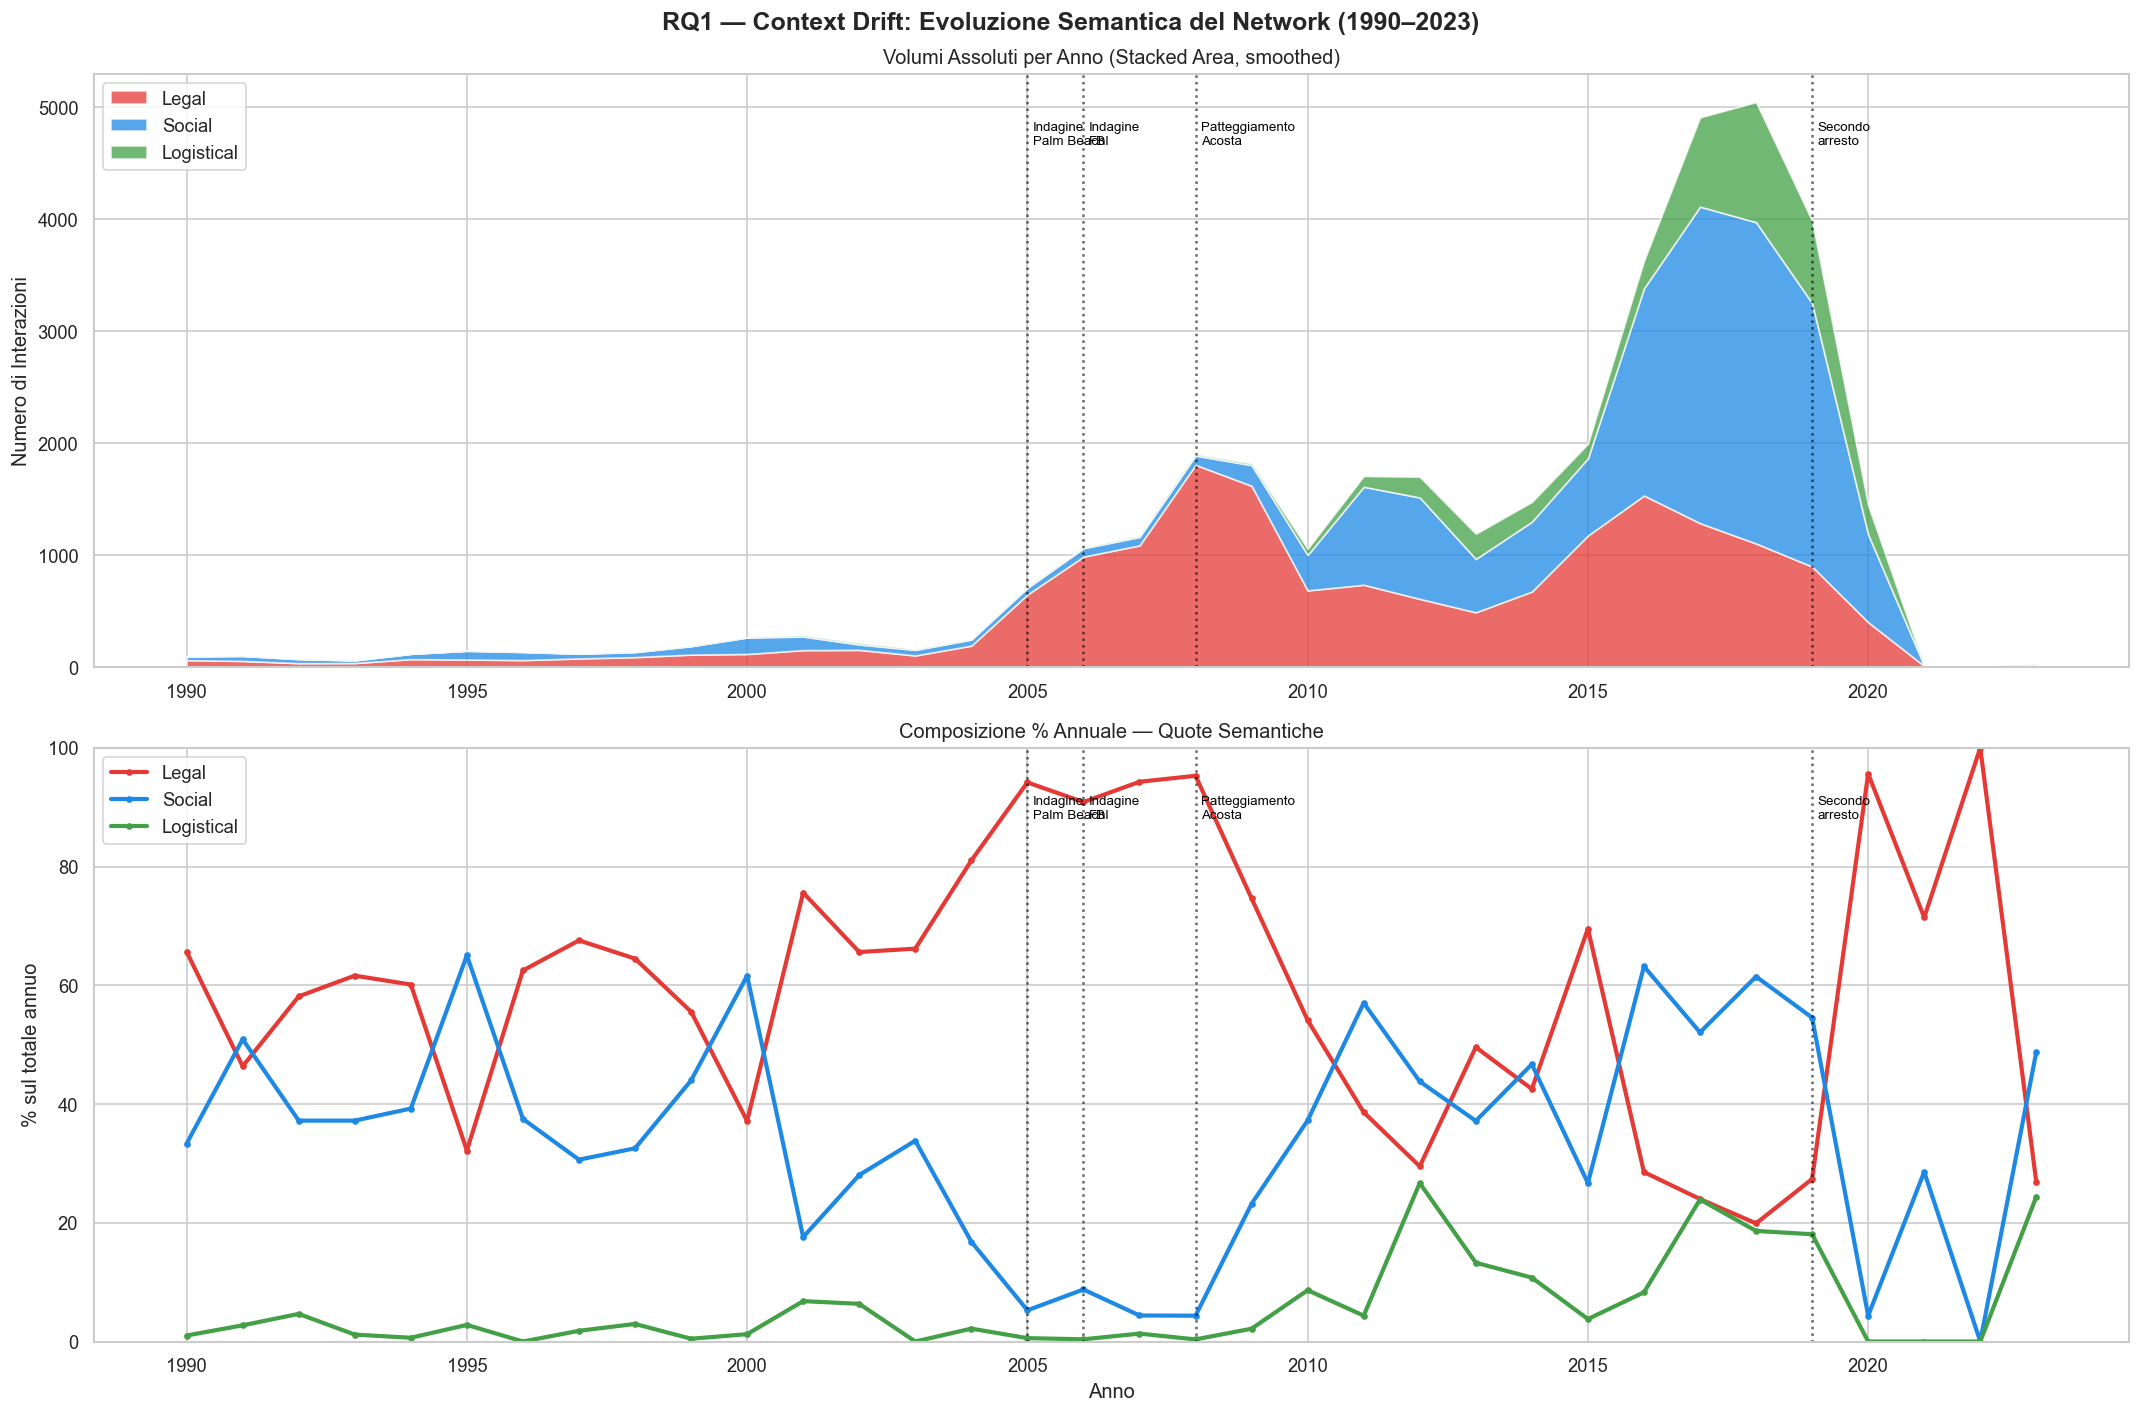


--- COMPOSIZIONE % PER FINESTRA TEMPORALE ---
                         Legal Social Logistical  N archi
Periodo                                                  
Pre-2005 (pre-indagine)  60.9%  36.7%       2.4%     2538
2005-2008 (indagini)     94.1%   5.3%       0.6%     5947
2009-2018 (post-patto)   35.8%  50.8%      13.4%    25831
2019+ (secondo arresto)  28.4%  53.7%      17.9%     2961


In [11]:
# Context Drift: Evoluzione Temporale delle Categorie
# La composizione semantica del network cambia nel tempo?
# Ipotesi: In corrispondenza degli shock giudiziari, la quota di archi classificati come 'Legal' aumenta 
# rispetto a 'Social' e 'Logistical'.

# Estrazione anno dagli archi (dal campo interaction_time del CSV)
df_clean['year'] = (
    df_clean['interaction_time']
    .astype(str)
    .str.extract(r'(19\d{2}|20\d{2})')
    [0]
    .astype(float)
)

df_temporal = df_clean[
    (df_clean['year'] >= 1990) &
    (df_clean['year'] <= 2023) &
    (df_clean['edge_label'].isin(['Legal','Social','Logistical']))
].copy()

# Distribuzione annuale per categoria
pivot = (
    df_temporal
    .groupby(['year','edge_label'])
    .size()
    .unstack(fill_value=0)
)

# Normalizzazione: quote % annuali (non volumi assoluti)
# Perché: Il volume cambia in base a quanti documenti abbiamo per quell'anno.
# Le quote ci dicono il MIX, non la quantità.
pivot_pct = pivot.div(pivot.sum(axis=1), axis=0) * 100

# Eventi giudiziari
JUDICIAL_EVENTS = {
    2005: "Indagine\nPalm Beach",
    2006: "Indagine\nFBI",
    2008: "Patteggiamento\nAcosta",
    2019: "Secondo\narresto"
}

fig, axes = plt.subplots(2, 1, figsize=(18, 12))
fig.suptitle('RQ1 — Context Drift: Evoluzione Semantica del Network (1990–2023)',
             fontsize=15, fontweight='bold')

# Grafico 1: volumi assoluti (stacked area)
pivot_smooth = pivot.rolling(window=2, min_periods=1).mean()
axes[0].stackplot(
    pivot_smooth.index,
    [pivot_smooth.get(c, pd.Series(0, index=pivot_smooth.index)) for c in ['Legal','Social','Logistical']],
    labels=['Legal','Social','Logistical'],
    colors=[PALETTE['Legal'], PALETTE['Social'], PALETTE['Logistical']],
    alpha=0.75
)
axes[0].set_title('Volumi Assoluti per Anno (Stacked Area, smoothed)', fontsize=12)
axes[0].set_ylabel('Numero di Interazioni')
axes[0].legend(loc='upper left')

# Grafico 2: quote percentuali (line chart)
for cat in ['Legal','Social','Logistical']:
    if cat in pivot_pct.columns:
        axes[1].plot(pivot_pct.index, pivot_pct[cat],
                     color=PALETTE[cat], linewidth=2.5, label=cat, marker='o', markersize=3)

axes[1].set_title('Composizione % Annuale — Quote Semantiche', fontsize=12)
axes[1].set_ylabel('% sul totale annuo')
axes[1].set_xlabel('Anno')
axes[1].legend()
axes[1].set_ylim(0, 100)

# Annotazioni eventi giudiziari su entrambi i grafici
for ax in axes:
    for year, label in JUDICIAL_EVENTS.items():
        if year in pivot_pct.index:
            ax.axvline(x=year, color='black', linestyle=':', alpha=0.6, linewidth=1.5)
            ax.text(year + 0.1, ax.get_ylim()[1] * 0.92, label,
                    fontsize=8, color='black', va='top', rotation=0)

plt.tight_layout()
plt.show()

# Tabella sintetica: variazione nelle finestre temporali
windows = {
    'Pre-2005 (pre-indagine)':   (1990, 2004),
    '2005-2008 (indagini)':      (2005, 2008),
    '2009-2018 (post-patto)':    (2009, 2018),
    '2019+ (secondo arresto)':   (2019, 2023)
}
print("\n--- COMPOSIZIONE % PER FINESTRA TEMPORALE ---")
rows = []
for label, (y0, y1) in windows.items():
    mask = (df_temporal['year'] >= y0) & (df_temporal['year'] <= y1)
    counts = df_temporal[mask]['edge_label'].value_counts(normalize=True) * 100
    row = {'Periodo': label}
    for cat in ['Legal','Social','Logistical']:
        row[cat] = f"{counts.get(cat, 0):.1f}%"
    row['N archi'] = mask.sum()
    rows.append(row)
df_windows = pd.DataFrame(rows).set_index('Periodo')
print(df_windows.to_string())


In [12]:
# Brokers - Unknown Entities come Structural Holes
# Domanda: Le entità Unknown hanno una Betweenness sproporzionata rispetto
# alle entità named? Se sì, occupano "buchi strutturali" (Burt, 2004).

# Classificazione nodi come Unknown o Named
df_centrality['is_unknown'] = df_centrality.index.map(is_unknown)

named_stats   = df_centrality[~df_centrality['is_unknown']]['betweenness'].describe()
unknown_stats = df_centrality[ df_centrality['is_unknown']]['betweenness'].describe()

print("--- BETWEENNESS: NAMED vs UNKNOWN ---")
print(f"\nEntità Named   ({(~df_centrality['is_unknown']).sum():,} nodi):")
print(named_stats.round(5).to_string())
print(f"\nEntità Unknown ({df_centrality['is_unknown'].sum():,} nodi):")
print(unknown_stats.round(5).to_string())

# Rapporto tra medie
ratio = unknown_stats['mean'] / named_stats['mean'] if named_stats['mean'] > 0 else 0
print(f"\nRapporto betweenness media Unknown/Named: {ratio:.2f}x")
if ratio > 1.5:
    print("→ Le entità Unknown hanno una betweenness SIGNIFICATIVAMENTE più alta.")
elif ratio > 1.0:
    print("→ Le entità Unknown hanno una betweenness leggermente più alta.")
else:
    print("→ Le entità Unknown NON sono broker strutturali privilegiati.")

# Top 15 Unknown per Betweenness
top_unknown = (
    df_centrality[df_centrality['is_unknown']]
    .sort_values('betweenness', ascending=False)
    .head(15)[['betweenness','pagerank','degree','community']]
    .round(5)
)
print("\n--- TOP 15 UNKNOWN PER BETWEENNESS ---")
print(top_unknown.to_string())

# Quota di betweenness totale del grafo detenuta dagli Unknown
total_btw = df_centrality['betweenness'].sum()
unknown_btw_share = df_centrality[df_centrality['is_unknown']]['betweenness'].sum()
print(f"\nQuota di betweenness totale detenuta da Unknown: {unknown_btw_share/total_btw*100:.1f}%")
print(f"Quota di nodi che sono Unknown: {df_centrality['is_unknown'].mean()*100:.1f}%")
print(f"→ Rapporto concentrazione: {(unknown_btw_share/total_btw) / df_centrality['is_unknown'].mean():.2f}x")


--- BETWEENNESS: NAMED vs UNKNOWN ---

Entità Named   (27,983 nodi):
count    27983.00000
mean         0.00001
std          0.00025
min          0.00000
25%          0.00000
50%          0.00000
75%          0.00000
max          0.03725

Entità Unknown (2,425 nodi):
count    2425.00000
mean        0.00001
std         0.00042
min         0.00000
25%         0.00000
50%         0.00000
75%         0.00000
max         0.02012

Rapporto betweenness media Unknown/Named: 1.87x
→ Le entità Unknown hanno una betweenness SIGNIFICATIVAMENTE più alta.

--- TOP 15 UNKNOWN PER BETWEENNESS ---
                                                                    betweenness  pagerank  degree  community
unknown person A                                                        0.02012   0.00576    3483         31
unknown person B                                                        0.00469   0.00072     458          1
unknown person C                                                        0.00143   0.00

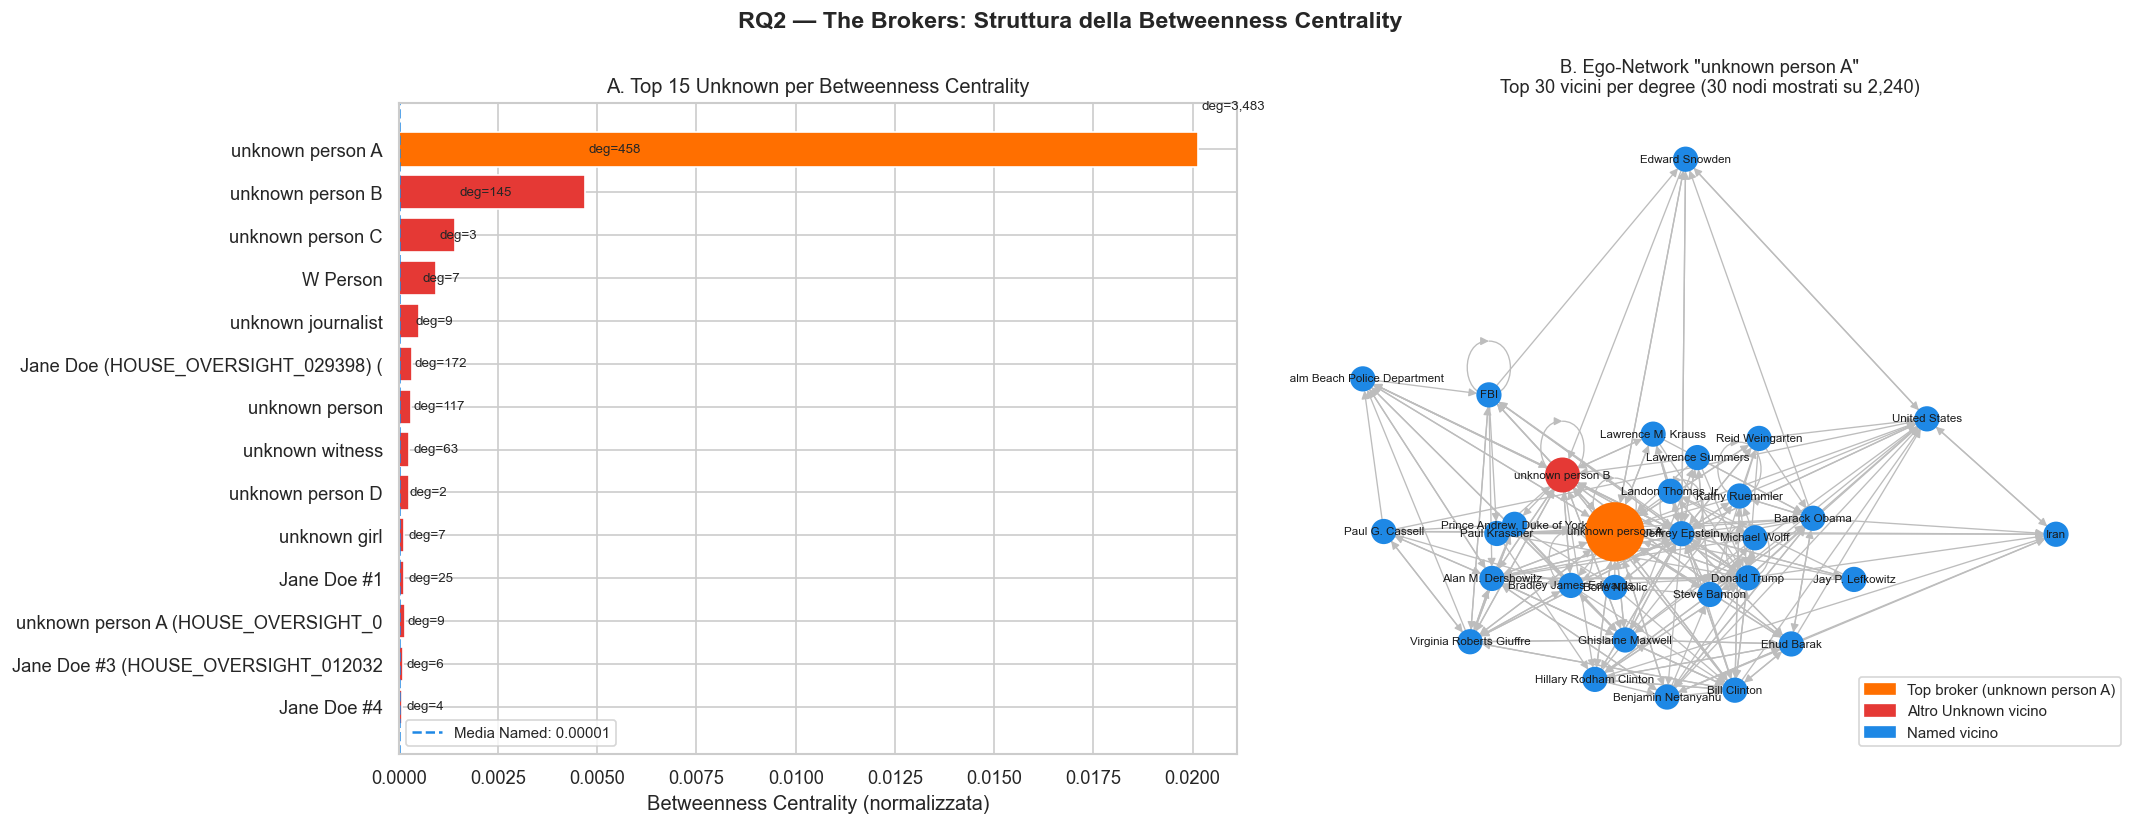

Top broker: unknown person A
Degree totale: 3,483
Betweenness: 0.02012
Community: 31


In [13]:
# Top Broker + Confronto Quantitativo

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('RQ2 — The Brokers: Struttura della Betweenness Centrality',
             fontsize=14, fontweight='bold')

# GRAFICO A: Top 15 Unknown per Betweenness (bar chart)
# Più leggibile del boxplot su distribuzioni power-law
top_unk = (
    df_centrality[df_centrality['is_unknown']]
    .sort_values('betweenness', ascending=False)
    .head(15)
)

colors_bar = ['#FF6F00' if i == 0 else '#E53935'
              for i in range(len(top_unk))]

axes[0].barh(
    [str(n)[:35] for n in top_unk.index[::-1]],
    top_unk['betweenness'].values[::-1],
    color=colors_bar[::-1], edgecolor='white'
)
axes[0].set_title('A. Top 15 Unknown per Betweenness Centrality', fontsize=12)
axes[0].set_xlabel('Betweenness Centrality (normalizzata)')

# Linea di riferimento: betweenness media dei Named
mean_named = df_centrality[~df_centrality['is_unknown']]['betweenness'].mean()
axes[0].axvline(x=mean_named, color='#1E88E5', linestyle='--', linewidth=1.5,
                label=f'Media Named: {mean_named:.5f}')
axes[0].legend(fontsize=9)

for i, (idx, row) in enumerate(top_unk.iloc[::-1].iterrows()):
    axes[0].text(row['betweenness'] + 0.0001, i,
                 f"deg={row['degree']:,}", va='center', fontsize=8)

# GRAFICO B: Ego-network ridotta (raggio 1, solo top 30 vicini per degree)
top_broker = top_unk.index[0]

# Prendiamo solo i 30 vicini con degree più alto
if top_broker in G_full:
    neighbors_all = list(G_full.predecessors(top_broker)) + \
                    list(G_full.successors(top_broker))
    
    # Ordiniamo per degree e prendiamo i top 30
    neighbors_top = sorted(
        set(neighbors_all),
        key=lambda n: degree_w.get(n, 0),
        reverse=True
    )[:30]
    
    ego_nodes = [top_broker] + neighbors_top
    ego = G_full.subgraph(ego_nodes).copy()
    
    node_colors = []
    node_sizes  = []
    for n in ego.nodes():
        if n == top_broker:
            node_colors.append('#FF6F00')
            node_sizes.append(1200)
        elif is_unknown(n):
            node_colors.append('#E53935')
            node_sizes.append(400)
        else:
            node_colors.append('#1E88E5')
            node_sizes.append(200)
    
    pos = nx.spring_layout(ego, seed=42, k=1.2)
    nx.draw_networkx(
        ego, pos, ax=axes[1],
        node_color=node_colors,
        node_size=node_sizes,
        font_size=7,
        arrows=True,
        edge_color='#BDBDBD',
        width=0.8,
        with_labels=True
    )
    axes[1].set_title(
        f'B. Ego-Network "{top_broker}"\n'
        f'Top 30 vicini per degree ({ego.number_of_nodes()} nodi mostrati su {len(neighbors_all):,})',
        fontsize=11
    )

from matplotlib.patches import Patch
legend = [
    Patch(color='#FF6F00', label='Top broker (unknown person A)'),
    Patch(color='#E53935', label='Altro Unknown vicino'),
    Patch(color='#1E88E5', label='Named vicino'),
]
axes[1].legend(handles=legend, loc='lower right', fontsize=9)
axes[1].axis('off')

plt.tight_layout()
plt.show()

print(f"Top broker: {top_broker}")
print(f"Degree totale: {degree_w[top_broker]:,}")
print(f"Betweenness: {betweenness[top_broker]:.5f}")
print(f"Community: {partition[top_broker]}")

In [14]:
# Contextual Influence: Metriche per Dominio
# Costruiamo tre sottografi (Legal-only, Social-only, Logistical-only) e
# ricalcoliamo le 4 metriche su ciascuno. Poi confrontiamo i ranking.

def compute_centrality_for_subgraph(G_sub, label):
    """Calcola le 4 metriche su un sottografo e restituisce un DataFrame."""
    if G_sub.number_of_nodes() == 0:
        return pd.DataFrame()
    
    deg = dict(G_sub.degree(weight='weight'))
    k_sub = min(500, G_sub.number_of_nodes())
    btw = nx.betweenness_centrality(
    G_sub, k=k_sub, normalized=True, weight='weight', seed=42
    )
    pr  = nx.pagerank(G_sub, alpha=0.85, weight='weight')
    
    try:
        eig = nx.eigenvector_centrality(G_sub, max_iter=1000, weight='weight')
    except nx.PowerIterationFailedConvergence:
        G_sub_u = G_sub.to_undirected(reciprocal=False)
        eig = nx.eigenvector_centrality(G_sub_u, max_iter=1000, weight='weight')
    
    return pd.DataFrame({
        f'degree_{label}':       deg,
        f'betweenness_{label}':  btw,
        f'pagerank_{label}':     pr,
        f'eigenvector_{label}':  eig
    })

subgraph_results = {}

for cat in ['Legal', 'Social', 'Logistical']:
    print(f"Calcolo metriche per sottografo: {cat}")
    # Filtriamo gli archi per categoria
    edges_cat = [(u, v, d) for u, v, d in G_full.edges(data=True) if d.get('category') == cat]
    G_sub = nx.DiGraph()
    G_sub.add_edges_from(edges_cat)
    # Copiamo i pesi
    for u, v, d in edges_cat:
        G_sub[u][v].update(d)
    
    subgraph_results[cat] = {
        'graph': G_sub,
        'metrics': compute_centrality_for_subgraph(G_sub, cat)
    }
    print(f"  {cat}: {G_sub.number_of_nodes()} nodi, {G_sub.number_of_edges()} archi")

# Merge di tutte le metriche
df_rq3 = df_centrality[['degree','betweenness','pagerank','eigenvector']].copy()
df_rq3.columns = ['degree_Full','betweenness_Full','pagerank_Full','eigenvector_Full']

for cat, data in subgraph_results.items():
    if not data['metrics'].empty:
        df_rq3 = df_rq3.join(data['metrics'], how='left')

df_rq3 = df_rq3.fillna(0)
print(f"\nDataFrame metriche combinato: {df_rq3.shape[0]} nodi × {df_rq3.shape[1]} colonne")


Calcolo metriche per sottografo: Legal
  Legal: 15181 nodi, 17611 archi
Calcolo metriche per sottografo: Social
  Social: 13703 nodi, 15073 archi
Calcolo metriche per sottografo: Logistical
  Logistical: 1683 nodi, 1737 archi

DataFrame metriche combinato: 30408 nodi × 16 colonne


In [15]:
# Rank Shift Matrix e Top Entità per Dominio
# Per ogni nodo calcoliamo il RANK (1 = più centrale) in ciascun dominio.
# Poi misuriamo lo "shift" = quanto cambia la posizione tra domini diversi.

TOP_N = 20   # quanti nodi analizzare in dettaglio

# Costruzione rank per PageRank in ogni dominio
for col in ['pagerank_Full','pagerank_Legal','pagerank_Social','pagerank_Logistical']:
    if col in df_rq3.columns:
        df_rq3[col.replace('pagerank','rank')] = df_rq3[col].rank(ascending=False, method='min')

# Tabella Top-20 per PageRank nel grafo completo
rank_cols = [c for c in df_rq3.columns if c.startswith('rank_')]
top20_full = (
    df_rq3[df_rq3['rank_Full'] <= TOP_N]
    .sort_values('rank_Full')[['pagerank_Full'] + rank_cols]
    .round(5)
)
print(f"--- TOP {TOP_N} PER PAGERANK (Grafo Completo) con rank per dominio ---")
print(top20_full.to_string())

# Rank Shift: differenza di posizione tra Full e Legal/Social/Logistical
if 'rank_Legal' in df_rq3.columns:
    df_rq3['shift_full_legal']      = (df_rq3['rank_Full'] - df_rq3['rank_Legal']).abs()
if 'rank_Social' in df_rq3.columns:
    df_rq3['shift_full_social']     = (df_rq3['rank_Full'] - df_rq3['rank_Social']).abs()
if 'rank_Logistical' in df_rq3.columns:
    df_rq3['shift_full_logistical'] = (df_rq3['rank_Full'] - df_rq3['rank_Logistical']).abs()

shift_cols = [c for c in df_rq3.columns if c.startswith('shift_')]
if shift_cols:
    df_rq3['total_shift'] = df_rq3[shift_cols].sum(axis=1)
    most_volatile = df_rq3.nlargest(10, 'total_shift')[['rank_Full'] + shift_cols + ['total_shift']]
    print("\n--- TOP 10 NODI PIÙ 'VOLATILI' (Cambiano più ranking tra domini) ---")
    print(most_volatile.round(1).to_string())


--- TOP 20 PER PAGERANK (Grafo Completo) con rank per dominio ---
                              pagerank_Full  rank_Full  rank_Legal  rank_Social  rank_Logistical
Jeffrey Epstein                     0.02738        1.0         1.0          1.0              1.0
unknown person A                    0.00576        2.0         2.0          3.0              2.0
Donald Trump                        0.00502        3.0         8.0          2.0              5.0
Alan M. Dershowitz                  0.00259        4.0         3.0         18.0             32.0
Edward Snowden                      0.00196        5.0         5.0         12.0              3.0
Bill Clinton                        0.00152        6.0        12.0          7.0             15.0
United States                       0.00148        7.0        11.0         10.0             65.0
Ehud Barak                          0.00133        8.0       441.0          4.0             28.0
Virginia Roberts Giuffre            0.00129        9.0       

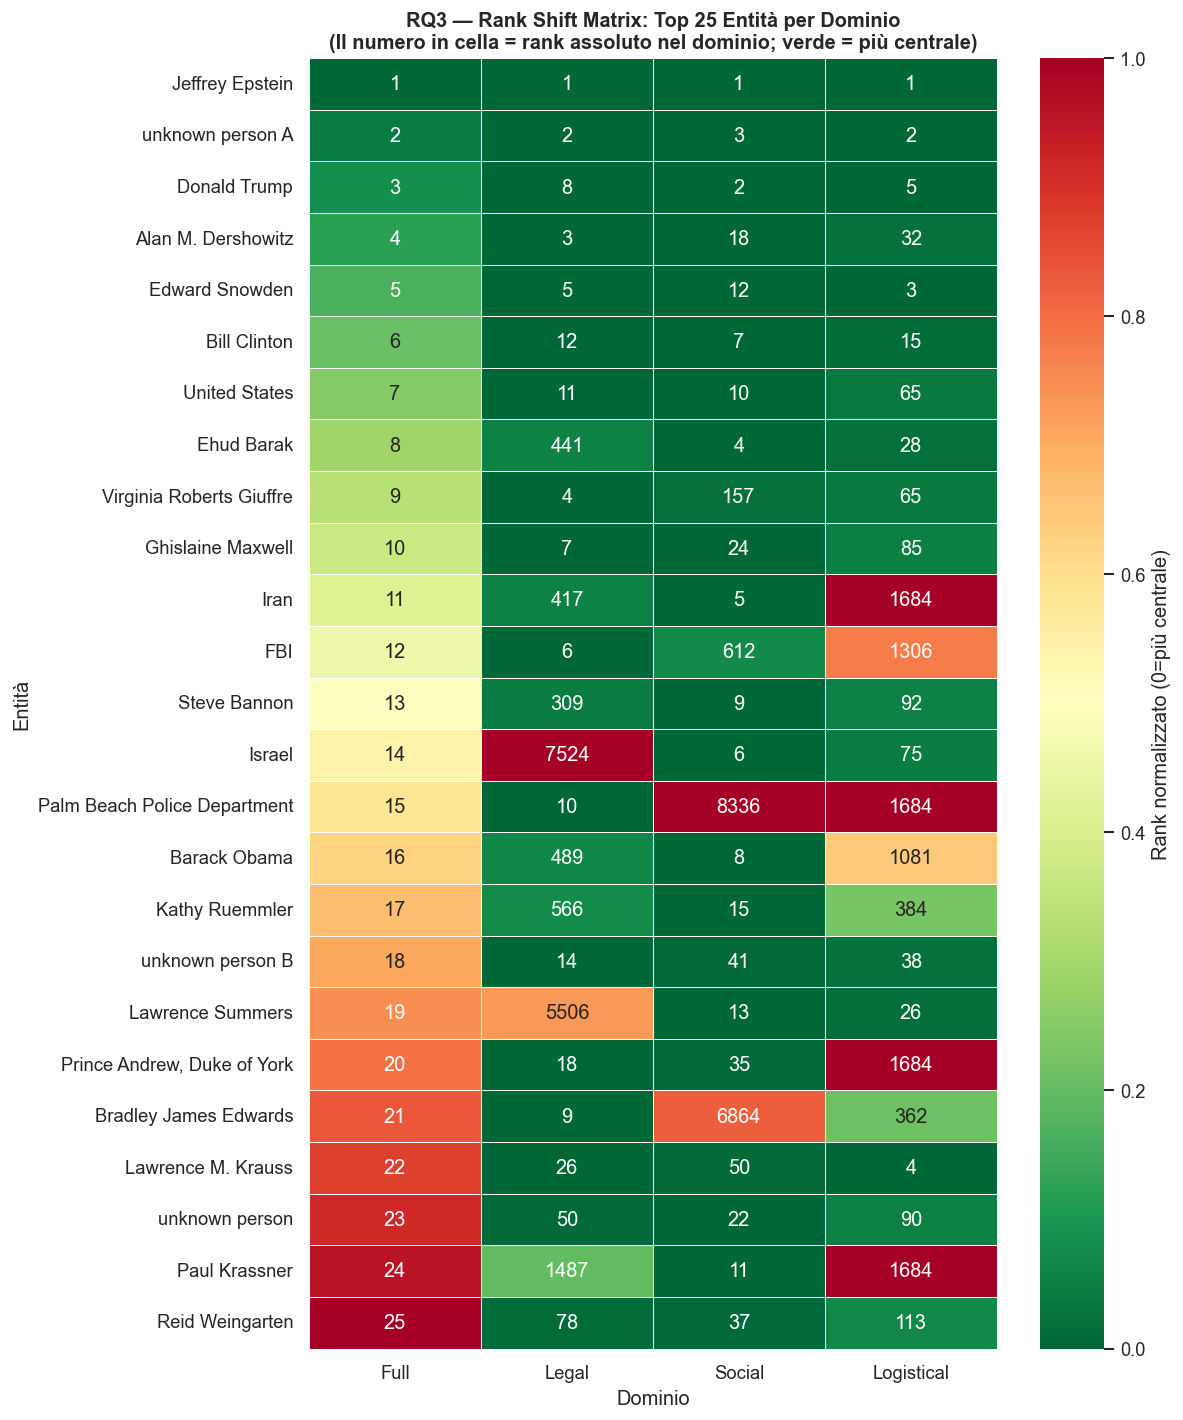

In [16]:
# Visualizziamo come i top nodi cambiano posizione nei 4 contesti.
# Un nodo stabile appare come una riga orizzontale uniforme.
# Un nodo volatile appare come una riga con valori molto diversi.

rank_cols_available = [c for c in ['rank_Full','rank_Legal','rank_Social','rank_Logistical']
                       if c in df_rq3.columns]

if len(rank_cols_available) >= 2:
    # Prendiamo i top 25 per PageRank nel grafo completo
    top25 = df_rq3.nsmallest(25, 'rank_Full')[rank_cols_available]
    
    # Normalizziamo i rank in [0,1] per la heatmap (rank 1 = più centrale = 0 sulla scala)
    top25_norm = top25.apply(lambda col: (col - col.min()) / (col.max() - col.min() + 1e-9))
    
    clean_cols = [c.replace('rank_','') for c in rank_cols_available]
    top25_norm.columns = clean_cols
    
    fig, ax = plt.subplots(figsize=(10, 12))
    sns.heatmap(
        top25_norm,
        ax=ax,
        cmap='RdYlGn_r',   # verde = rank alto (centrale), rosso = rank basso
        annot=top25[rank_cols_available].values.astype(int),
        fmt='d',
        linewidths=0.5,
        cbar_kws={'label': 'Rank normalizzato (0=più centrale)'}
    )
    ax.set_title('RQ3 — Rank Shift Matrix: Top 25 Entità per Dominio\n'
                 '(Il numero in cella = rank assoluto nel dominio; verde = più centrale)',
                 fontsize=12, fontweight='bold')
    ax.set_xlabel('Dominio')
    ax.set_ylabel('Entità')
    plt.tight_layout()
    plt.show()
else:
    print("Dati insufficienti per la heatmap. Verifica che tutti i sottografi abbiano nodi.")


In [17]:
# Pruning Dinamico per il Browser
# Invece di un MIN_DEGREE fisso, usiamo un approccio percentile-based
# che mantiene sempre i top-K% dei nodi per PageRank.
# Questo garantisce che i nodi più rilevanti siano sempre inclusi indipendentemente
# dalla scala del dataset.

TARGET_NODE_MAX = 1200

# Ordiniamo per PageRank decrescente
pagerank_series = pd.Series(pagerank).sort_values(ascending=False)
total_nodes = len(pagerank_series)

pagerank_series_pruned = pagerank_series[
    pagerank_series.index.isin(valid_nodes_pruned)
]

if len(pagerank_series_pruned) <= TARGET_NODE_MAX:
    pagerank_threshold = 0.0
else:
    pagerank_threshold = pagerank_series_pruned.iloc[TARGET_NODE_MAX]

valid_nodes = set(
    pagerank_series_pruned[pagerank_series_pruned >= pagerank_threshold].index
)

print(f"Nodi dopo entity pruning:     {len(pagerank_series_pruned):,}")
print(f"Nodi dopo PageRank threshold: {len(valid_nodes):,}")
print(f"PageRank threshold applicato: {pagerank_threshold:.6f}")

print(f"Nodi totali nel grafo: {total_nodes:,}")
print(f"Nodi selezionati per la UI (PageRank ≥ {pagerank_threshold:.6f}): {len(valid_nodes):,}")
print(f"Target era: ≤ {TARGET_NODE_MAX}")


Nodi dopo entity pruning:     30,408
Nodi dopo PageRank threshold: 1,201
PageRank threshold applicato: 0.000060
Nodi totali nel grafo: 30,408
Nodi selezionati per la UI (PageRank ≥ 0.000060): 1,201
Target era: ≤ 1200


In [18]:
# Export JSON per React/WebGL
# Ogni nodo porta tutte le metriche calcolate + la label is_unknown.
# Ogni arco porta il peso e la categoria semantica (per il filtro nella UI).

nodes_out = []
for node in valid_nodes:
    nodes_out.append({
        "id":          str(node),
        "label":       str(node),
        # Dimensione visiva proporzionale al degree pesato
        "val":         float(degree_w.get(node, 1)),
        # Metriche analitiche (per tooltip e filtri nella UI)
        "betweenness": round(float(betweenness.get(node, 0)), 6),
        "pagerank":    round(float(pagerank.get(node, 0)), 6),
        "eigenvector": round(float(eigenvector.get(node, 0)), 6),
        # Community (per la colorazione)
        "group":       int(partition.get(node, -1)),
        # Flag analitico (per il filtro RQ2 nella UI)
        "is_unknown":  bool(is_unknown(node))
    })

links_out = []
for u, v, data in G_full.edges(data=True):
    if u in valid_nodes and v in valid_nodes:
        links_out.append({
            "source":   str(u),
            "target":   str(v),
            "weight":   int(data.get('weight', 1)),
            "category": str(data.get('category', 'Unknown'))
        })

web_graph = {
    "metadata": {
        "total_nodes": len(nodes_out),
        "total_links": len(links_out),
        "n_communities": n_communities,
        "categories": ["Legal", "Social", "Logistical"],
        "pagerank_threshold": float(pagerank_threshold)
    },
    "nodes": nodes_out,
    "links": links_out
}

output_json_path = '../data/web_graph_data.json'
with open(output_json_path, 'w', encoding='utf-8') as f:
    json.dump(web_graph, f, ensure_ascii=False, separators=(',', ':'))  # compact JSON

size_mb = len(json.dumps(web_graph).encode('utf-8')) / 1_048_576
print(f"Export completato:")
print(f"  Nodi: {len(nodes_out):,}")
print(f"  Archi: {len(links_out):,}")
print(f"  Dimensione file: {size_mb:.2f} MB")
print(f"  Salvato in: {output_json_path}")


Export completato:
  Nodi: 1,201
  Archi: 3,402
  Dimensione file: 0.51 MB
  Salvato in: ../data/web_graph_data.json


In [19]:
# Export CSV per Documentazione

# 1. Tabella centralità completa
df_centrality.to_csv('../data/centrality_full.csv')
print("Salvato: centrality_full.csv")

# 2. Tabella RQ3 (rank shift)
df_rq3.to_csv('../data/rq3_rank_shift.csv')
print("Salvato: rq3_rank_shift.csv")

# 3. Tabella RQ1 (distribuzione temporale per anno/categoria)
if 'pivot_pct' in dir():
    pivot_pct.to_csv('../data/rq1_temporal_distribution.csv')
    print("Salvato: rq1_temporal_distribution.csv")

# 4. Sintesi finale
print(f"  Grafo analizzato: {G_full.number_of_nodes():,} nodi, {G_full.number_of_edges():,} archi")
print(f"  Comunità rilevate: {n_communities}")
print(f"  File JSON per UI: web_graph_data.json ({size_mb:.2f} MB)")
print(f"  File CSV esportati: 3")


Salvato: centrality_full.csv
Salvato: rq3_rank_shift.csv
Salvato: rq1_temporal_distribution.csv
  Grafo analizzato: 30,408 nodi, 34,421 archi
  Comunità rilevate: 4983
  File JSON per UI: web_graph_data.json (0.51 MB)
  File CSV esportati: 3


In [20]:
import json
from collections import defaultdict

path = '/Users/bernadettescocca/Epstein-Network-Analysis/data/web_graph_data.json'
data = json.load(open(path))

# Conta archi per categoria per ogni nodo
domain_count = defaultdict(lambda: {'Legal': 0, 'Social': 0, 'Logistical': 0})

for link in data['links']:
    src = link['source']
    tgt = link['target']
    cat = link.get('category', 'Social')
    if cat in domain_count[src]:
        domain_count[src][cat] += 1
    if cat in domain_count[tgt]:
        domain_count[tgt][cat] += 1

# Assegna dominio prevalente a ogni nodo
for node in data['nodes']:
    counts = domain_count[node['id']]
    total  = sum(counts.values())
    if total == 0:
        node['dominant_domain'] = 'Social'
        node['domain_legal_pct']      = 0
        node['domain_social_pct']     = 0
        node['domain_logistical_pct'] = 0
    else:
        node['dominant_domain'] = max(counts, key=counts.get)
        node['domain_legal_pct']      = round(counts['Legal']      / total * 100, 1)
        node['domain_social_pct']     = round(counts['Social']     / total * 100, 1)
        node['domain_logistical_pct'] = round(counts['Logistical'] / total * 100, 1)

# Salva
json.dump(data, open(path, 'w'), ensure_ascii=False, separators=(',', ':'))

# Verifica
sample = next(n for n in data['nodes'] if n['id'] == 'Jeffrey Epstein')
print(json.dumps(sample, indent=2))

{
  "id": "Jeffrey Epstein",
  "label": "Jeffrey Epstein",
  "val": 14467.0,
  "betweenness": 0.037247,
  "pagerank": 0.027382,
  "eigenvector": 0.560903,
  "group": 5,
  "is_unknown": false,
  "dominant_domain": "Social",
  "domain_legal_pct": 33.8,
  "domain_social_pct": 59.1,
  "domain_logistical_pct": 7.0
}
